<a href="https://colab.research.google.com/github/inosven/Neural-Networks-Zero-to-Hero/blob/main/makemore_bigram_excercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
with open('/content/drive/MyDrive/Colab Notebooks/Zero2Hero_Karpathy/Data/names.txt','r') as f:
  words = f.read().splitlines()

Mounted at /content/drive


In [2]:
words[:3]

['emma', 'olivia', 'ava']

In [9]:
chars = sorted(list(set(''.join(words))))

stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos = {i:s for s,i in stoi.items()}
print(itos)


{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [11]:
import torch

In [12]:
X, Y = [], []
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1,ch2,ch3 in zip(chs,chs[1:],chs[2:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    ix3=stoi[ch3]
    # print(ix1,ix2,ix3)
  X.append([ix1,ix2])
  Y.append(ix3)
X = torch.tensor(X)
Y = torch.tensor(Y)

In [14]:
X.shape, Y.shape

(torch.Size([32033, 2]), torch.Size([32033]))

In [15]:
import torch.nn.functional as F

In [21]:
xenc = F.one_hot(X,num_classes=27).float()
xenc.shape

torch.Size([32033, 2, 27])

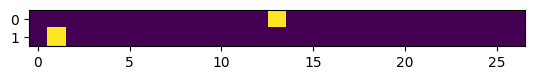

In [20]:
from matplotlib import pyplot as plt
plt.imshow(xenc[0])

In [22]:
g = torch.Generator().manual_seed(22123123)

In [23]:
W = torch.randn((27*2,27),generator=g, requires_grad=True)
logits = xenc.view(-1,27*2) @ W

In [27]:
for _ in range(100):
  #foward
  logits = xenc.view(-1,27*2) @ W
  counts = logits.exp()
  probs = counts / counts.sum(1, keepdim=True)
  loss=-probs[torch.arange(Y.shape[0]),Y].log().mean()
  print(loss.item())
  #backward
  W.grad=None
  loss.backward()

  #update
  W.data += 0.01*W.grad

nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
